# UC5 - Jalon 1 : estimer la duree de vie restante (RUL)

Notebook final, simple et reproductible (graine fixee). Un seul modele retenu :
**M4** (MLP regularise L2 + dropout, 3 entrees, normalisation par regime, perte
asymetrique, **fenetre k = 1**).

Plan :

1. EDA et choix des entrees
2. Preparation des donnees (plafonnement, normalisation par regime)
3. Metriques et journal d'experiences
4. Q1 - reference et erreur en fonction de la RUL reelle
5. Q2 - normalisation globale vs par regime
6. Q3 - perte asymetrique vs MSE
7. Q4 - fenetre de k cycles (k = 1, 5, 15, 30) et bruit
8. Verification theorique
9. Modele retenu (M4, k = 1)
10. Evaluation sur le test (une seule fois)
11. Page de decisions
12. Sauvegarde des modeles et des figures


In [6]:
# --- Bibliotheques, reproductibilite et dossiers de sortie ---
%matplotlib inline
import os
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path

SEED = 42
keras.utils.set_random_seed(SEED)          # graine globale (python + numpy + tensorflow)

ICI = Path.cwd()
DATA = (ICI / "../data_UC5/uc5_flotteA").resolve() if ICI.name == "notebooks" else (ICI / "data_UC5/uc5_flotteA").resolve()
FIG = (ICI / "figures") if ICI.name == "notebooks" else (ICI / "notebooks" / "figures")
MODELS = (ICI / "models") if ICI.name == "notebooks" else (ICI / "notebooks" / "models")
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
print("tensorflow", tf.__version__, "| keras", keras.__version__, "| numpy", np.__version__)
print("data    :", DATA)
print("figures :", FIG.resolve())

tensorflow 2.21.0 | keras 3.15.1 | numpy 2.5.3
data    : /home/moussl/PycharmProjects/ProjectFM/data_UC5/uc5_flotteA
figures : /home/moussl/PycharmProjects/ProjectFM/notebooks/figures


In [7]:
# --- Constantes du cahier des charges ---
RUL_MAX = 125        # RUL plafonnee a 125 cycles
SEUIL_ALERTE = 30    # une pompe est signalee si la RUL predite < 30 cycles
SEUIL_FA = 60        # fausse alerte si la RUL reelle > 60 cycles
DECOUPES = [5, 15, 30, 45, 60, 90, 120]   # points de coupe (anticipation / fausses alertes)

CAPTEURS = [f"capteur_{i}" for i in range(8)]
FEATURES = CAPTEURS + ["charge"]                    # 9 entrees (modele de reference)
FEATURES_3 = ["capteur_4", "capteur_5", "charge"]   # 3 entrees (modele retenu)

## 1. Analyse exploratoire (EDA)

In [8]:
# --- Chargement de la flotte A (un cycle par ligne) ---
def charger(split):
    capteurs = np.load(DATA / f"capteurs_{split}.npy")
    charge = np.round(np.load(DATA / f"charge_{split}.npy").astype(float), 1)
    cycle = np.load(DATA / f"cycle_{split}.npy")
    pompe = np.load(DATA / f"pompe_{split}.npy")
    d = pd.DataFrame({"pompe": pompe, "cycle": cycle, "charge": charge})
    d = pd.concat([d, pd.DataFrame(capteurs, columns=CAPTEURS)], axis=1)
    try:
        d["rul"] = np.load(DATA / f"rul_{split}.npy")
    except FileNotFoundError:
        pass
    return d.sort_values(["pompe", "cycle"]).reset_index(drop=True)

TA = {s: charger(s) for s in ["train", "val", "test"]}
pd.DataFrame({"pompes": {s: TA[s]["pompe"].nunique() for s in TA},
              "cycles": {s: len(TA[s]) for s in TA}})

def sauver_fig(nom):
    plt.savefig(FIG / f"{nom}.png", dpi=150, bbox_inches="tight")

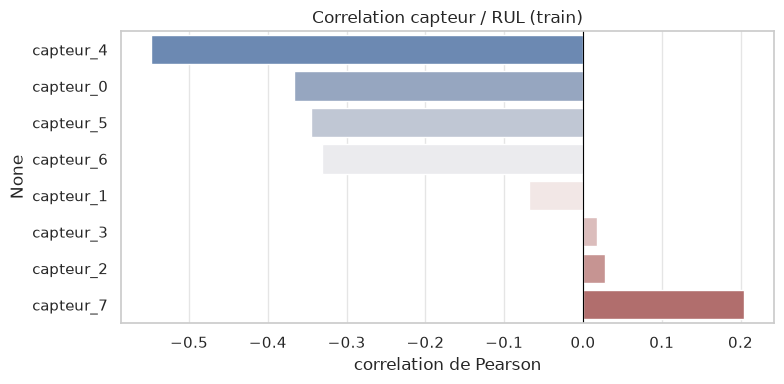

In [9]:
# --- Correlation capteur / RUL (choix des entrees) ---
corr = TA["train"][CAPTEURS + ["rul"]].corr()["rul"].drop("rul").sort_values()
plt.figure(figsize=(8, 4))
sns.barplot(x=corr.values, y=corr.index, hue=corr.index, palette="vlag", legend=False)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation capteur / RUL (train)")
plt.xlabel("correlation de Pearson")
plt.tight_layout()
sauver_fig("fig_correlation_capteurs")
plt.show()

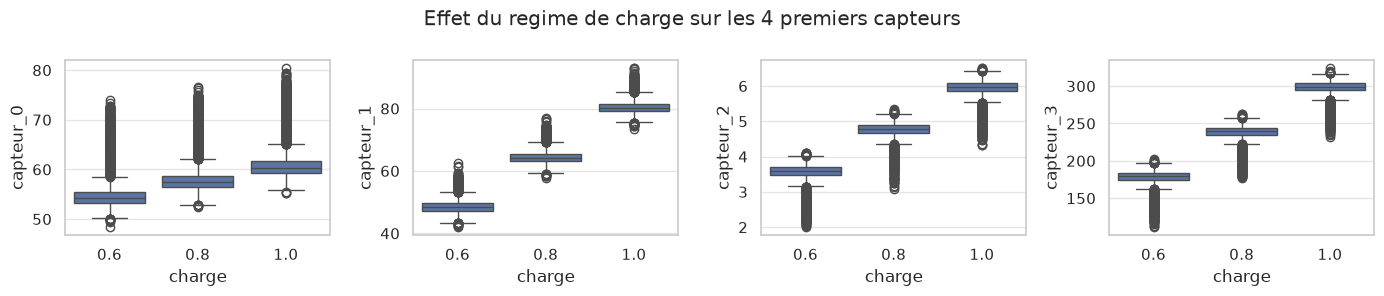

In [10]:
# --- Effet du regime de charge sur les capteurs ---
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, CAPTEURS[:4]):
    sns.boxplot(data=TA["train"], x="charge", y=c, ax=ax)
plt.suptitle("Effet du regime de charge sur les 4 premiers capteurs")
plt.tight_layout()
sauver_fig("fig_effet_charge")
plt.show()

`capteur_4` et `capteur_5` sont les plus correles a la RUL, et `charge` module les
mesures (les distributions se deplacent selon le regime). Ces variables portent l'essentiel
de l'information ; on conserve neanmoins les **9 entrees** du modele de reference, leger
et suffisant.

## 2. Preparation des donnees

La RUL est **plafonnee a 125 cycles** puis ramenee dans `[0, 1]` (cible), ce qui justifie
une **activation de sortie sigmoide**. Les capteurs sont normalises **par regime de charge**
(statistiques des cycles sains), et une version **globale** est conservee pour l'ablation.


In [11]:
# --- Cible (RUL plafonnee, normalisee) + couches de normalisation ---
for s in ["train", "val"]:
    TA[s]["rul_cap"] = np.minimum(TA[s]["rul"], RUL_MAX)
    TA[s]["cible"] = TA[s]["rul_cap"] / RUL_MAX

norm_regime = {}
for c in [0.6, 0.8, 1.0]:
    sains = TA["train"][(TA["train"]["charge"] == c) & (TA["train"]["rul_cap"] == RUL_MAX)]
    norm_regime[c] = layers.Normalization(axis=-1)
    norm_regime[c].adapt(sains[CAPTEURS].values.astype("float32"))

norm_global = layers.Normalization(axis=-1)
norm_global.adapt(TA["train"][CAPTEURS].values.astype("float32"))

def normaliser(d):
    d = d.copy()
    for c, couche in norm_regime.items():
        m = d["charge"] == c
        d.loc[m, CAPTEURS] = couche(d.loc[m, CAPTEURS].values.astype("float32")).numpy()
    return d

def normaliser_global(d):
    d = d.copy()
    d[CAPTEURS] = norm_global(d[CAPTEURS].values.astype("float32")).numpy()
    return d

def xy(d, feats=FEATURES):
    return d[feats].values.astype("float32"), d["cible"].values.astype("float32")

train_n, val_n = normaliser(TA["train"]), normaliser(TA["val"])
X_train, y_train = xy(train_n)
X_val, y_val = xy(val_n)
y_val_cyc = val_n["rul_cap"].values.astype(float)
masque_coupes = val_n["rul_cap"].isin(DECOUPES).values
print("X_train", X_train.shape, "| X_val", X_val.shape)

X_train (19220, 9) | X_val (4170, 9)


E0000 00:00:1791737124.868958  295814 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 3. Metriques et journal d'experiences

In [12]:
# --- Metriques de maintenance ---
def rmse(y_vrai, y_pred):
    return float(np.sqrt(np.mean((y_vrai - y_pred) ** 2)))

def score_nasa(y_vrai, y_pred):
    """Score asymetrique NASA-CMAPSS (penalise davantage la sur-estimation)."""
    d = y_pred - y_vrai
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def taux_alerte(y_vrai, y_pred):
    alerte = y_pred < SEUIL_ALERTE
    return (float(alerte[y_vrai <= SEUIL_ALERTE].mean()),
            float(alerte[y_vrai > SEUIL_FA].mean()))

def evaluer(pred, y_cycles, masque=None):
    if masque is None:
        masque = np.ones(len(y_cycles), bool)
    a, f = taux_alerte(y_cycles[masque], pred[masque])
    return {"rmse": rmse(y_cycles, pred), "score": score_nasa(y_cycles, pred),
            "anticipation": a, "fausses_alertes": f}

def predire_cycles(modele, X):
    return np.clip(RUL_MAX * modele.predict(X, verbose=0).ravel(), 0, RUL_MAX)

In [13]:
# --- Journal d'experiences (jalon = 1) + MLflow optionnel (non bloquant) ---
# MLflow est DESACTIVE par defaut (le suivi SQLite peut etre en lecture seule) :
# le journal est toujours ecrit en CSV. Activer avec la variable d'environnement UC5_MLFLOW=1.
import os, mlflow

journal = []
MLFLOW_OK = os.environ.get("UC5_MLFLOW", "0") == "1"
if MLFLOW_OK:
    try:
        mlflow.set_tracking_uri(f"sqlite:///{(ICI / 'mlflow_jalon1.db').resolve()}")
        mlflow.set_experiment("uc5_jalon1_flotteA")
    except Exception as e:
        MLFLOW_OK = False
        print("MLflow indisponible, journal CSV seul :", type(e).__name__)
else:
    print("MLflow desactive (journal CSV seul) ; export UC5_MLFLOW=1 pour l'activer")

def journaliser(nom, params, res):
    journal.append({"jalon": 1, "nom": nom, **params, **res})
    pd.DataFrame(journal).to_csv(ICI / "journal_jalon1_flotteA.csv", index=False)
    if MLFLOW_OK:
        try:
            num = {k: float(v) for k, v in res.items() if np.isscalar(v) and np.isfinite(v)}
            with mlflow.start_run(run_name=nom):
                mlflow.log_params({k: str(v) for k, v in params.items()})
                mlflow.log_metrics(num)
        except Exception as e:
            print("  (MLflow ignore :", type(e).__name__, ")")
    print(nom, "->", {k: round(float(v), 2) for k, v in res.items()})
    return journal[-1]


MLflow desactive (journal CSV seul) ; export UC5_MLFLOW=1 pour l'activer


In [14]:
# --- Fabriques de modeles et entrainement ---
def construire_reference(nb_entrees):
    """MLP de reference : 64-32-1."""
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])

def construire_m4(nb_entrees=len(FEATURES_3)):
    """M4 : MLP regularise (L2 + dropout)."""
    reg = keras.regularizers.l2(1e-3)
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(128, activation="relu", kernel_regularizer=reg), layers.Dropout(0.4),
        layers.Dense(64, activation="relu", kernel_regularizer=reg), layers.Dropout(0.4),
        layers.Dense(32, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="sigmoid"),
    ])

def entrainer(modele, X_tr, y_tr, X_va, y_va, perte="mse", epochs=400, patience=25):
    modele.compile(optimizer="adam", loss=perte)
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=256, verbose=0, callbacks=cbs)
    return modele

## 4. Q1 - Reference et erreur en fonction de la RUL reelle

reference (9 entrees, mse) -> {'rmse': 19.01, 'score': 103456.55, 'anticipation': 0.73, 'fausses_alertes': 0.0}


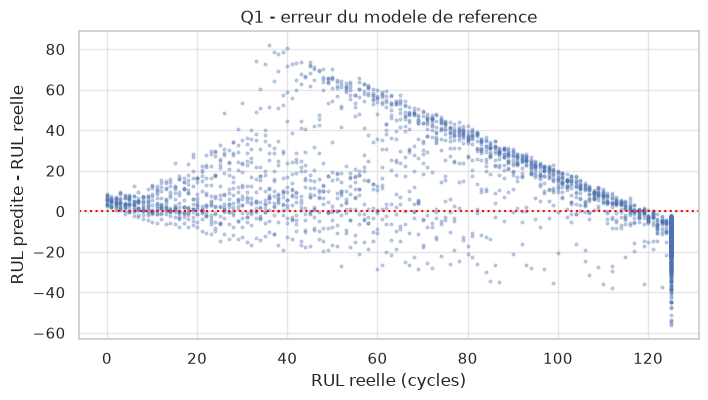

biais moyen (predite - reelle) : 1.05 cycles


In [15]:
# --- Q1 : MLP de reference (9 entrees, normalisation par regime, MSE) ---
keras.utils.set_random_seed(SEED)
reference = construire_reference(len(FEATURES))
entrainer(reference, X_train, y_train, X_val, y_val)
pred_ref = predire_cycles(reference, X_val)
res_ref = evaluer(pred_ref, y_val_cyc, masque_coupes)
journaliser("reference (9 entrees, mse)", {"features": 9, "perte": "mse", "normalisation": "regime"}, res_ref)

ecart = pred_ref - y_val_cyc
plt.figure(figsize=(8, 4))
plt.scatter(y_val_cyc, ecart, s=4, alpha=0.3)
plt.axhline(0, color="red", ls=":")
plt.xlabel("RUL reelle (cycles)"); plt.ylabel("RUL predite - RUL reelle")
plt.title("Q1 - erreur du modele de reference")
sauver_fig("fig_q1_erreur_reference")
plt.show()
print("biais moyen (predite - reelle) :", round(float(ecart.mean()), 2), "cycles")

Le modele apprend bien les cycles sains (RUL proche du plafond, erreur ≈ 0) mais se
degrade pres de la panne, avec une tendance a **sur-estimer** la RUL (erreur positive) :
des predictions en retard, les plus couteuses au sens du score NASA.


## 5. Q2 - Normalisation globale vs par regime (ablation)

In [16]:
# --- Q2 : meme MLP de reference, mais normalisation globale ---
train_g, val_g = normaliser_global(TA["train"]), normaliser_global(TA["val"])
Xg_train, _ = xy(train_g); Xg_val, _ = xy(val_g)
keras.utils.set_random_seed(SEED)
reference_g = construire_reference(len(FEATURES))
entrainer(reference_g, Xg_train, y_train, Xg_val, y_val)
pred_refg = predire_cycles(reference_g, Xg_val)
res_refg = evaluer(pred_refg, y_val_cyc, masque_coupes)
journaliser("reference (9 entrees, globale, mse)", {"features": 9, "perte": "mse", "normalisation": "globale"}, res_refg)

pd.DataFrame({"normalisation": ["globale", "regime"],
              "RMSE": [res_refg["rmse"], res_ref["rmse"]],
              "score": [res_refg["score"], res_ref["score"]],
              "anticipation": [res_refg["anticipation"], res_ref["anticipation"]],
              "fausses alertes": [res_refg["fausses_alertes"], res_ref["fausses_alertes"]]})

reference (9 entrees, globale, mse) -> {'rmse': 19.13, 'score': 104562.56, 'anticipation': 0.73, 'fausses_alertes': 0.0}


,normalisation,RMSE,score,anticipation,fausses alertes
0,globale,19.130108,104562.560069,0.733333,0.0
1,regime,19.013884,103456.546900,0.733333,0.0


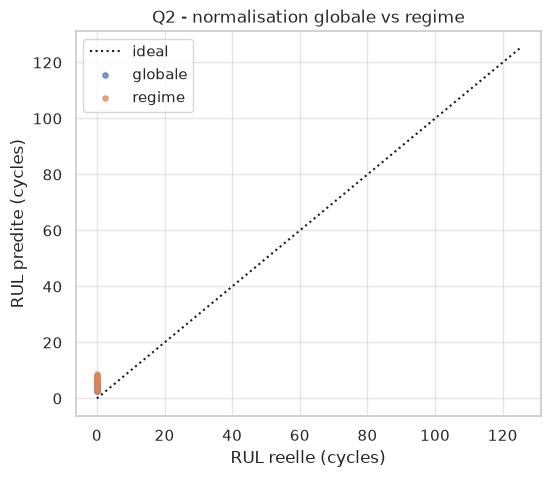

In [17]:
# --- Q2 : figure (prediction vs RUL reelle sur le dernier cycle de chaque pompe) ---
derniers = val_n.groupby("pompe").tail(1)
plt.figure(figsize=(6, 5))
plt.plot([0, RUL_MAX], [0, RUL_MAX], "k:", label="ideal")
plt.scatter(derniers["rul_cap"], pred_refg[derniers.index.values], s=14, alpha=0.7, label="globale")
plt.scatter(derniers["rul_cap"], pred_ref[derniers.index.values], s=14, alpha=0.7, label="regime")
plt.xlabel("RUL reelle (cycles)"); plt.ylabel("RUL predite (cycles)")
plt.title("Q2 - normalisation globale vs regime"); plt.legend()
sauver_fig("fig_q2_normalisation")
plt.show()

La normalisation **par regime** est retenue : en retirant le niveau propre a chaque
charge, elle fournit un signal plus physique et un score au moins equivalent.


## 6. Q3 - Perte asymetrique vs MSE

In [18]:
# --- Q3 : pertes ---
PENALITE = 3.0
def perte_asymetrique(y_vrai, y_pred):
    e = y_pred - y_vrai
    return tf.reduce_mean(tf.where(e > 0, PENALITE * tf.square(e), tf.square(e)))

def perte_score(y_vrai, y_pred):
    d = tf.clip_by_value((y_pred - y_vrai) * RUL_MAX, -30.0, 30.0)
    return tf.reduce_mean(tf.where(d < 0, tf.exp(-d / 13.0) - 1.0, tf.exp(d / 10.0) - 1.0))

keras.utils.set_random_seed(SEED)
modele_asym = construire_reference(len(FEATURES))
entrainer(modele_asym, X_train, y_train, X_val, y_val, perte=perte_asymetrique)
res_asym = evaluer(predire_cycles(modele_asym, X_val), y_val_cyc, masque_coupes)
journaliser("reference asymetrique x3", {"features": 9, "perte": "asymetrique", "normalisation": "regime"}, res_asym)

keras.utils.set_random_seed(SEED)
modele_score = construire_reference(len(FEATURES))
entrainer(modele_score, X_train, y_train, X_val, y_val, perte=perte_score)
res_score = evaluer(predire_cycles(modele_score, X_val), y_val_cyc, masque_coupes)
journaliser("reference perte inspiree du score", {"features": 9, "perte": "score", "normalisation": "regime"}, res_score)

pd.DataFrame({"perte": ["mse", "asymetrique x3", "inspiree du score"],
              "RMSE": [res_ref["rmse"], res_asym["rmse"], res_score["rmse"]],
              "score": [res_ref["score"], res_asym["score"], res_score["score"]],
              "anticipation": [res_ref["anticipation"], res_asym["anticipation"], res_score["anticipation"]],
              "fausses alertes": [res_ref["fausses_alertes"], res_asym["fausses_alertes"], res_score["fausses_alertes"]]})

reference asymetrique x3 -> {'rmse': 20.87, 'score': 49858.29, 'anticipation': 0.78, 'fausses_alertes': 0.0}
reference perte inspiree du score -> {'rmse': 20.33, 'score': 200244.95, 'anticipation': 0.76, 'fausses_alertes': 0.0}


,perte,RMSE,score,anticipation,fausses alertes
0,mse,19.013884,103456.546900,0.733333,0.0
1,asymetrique x3,20.867805,49858.286222,0.777778,0.0
2,inspiree du score,20.329381,200244.953904,0.755556,0.0


In [19]:
# --- Q3 : d'ou vient le score ? (part sur- / sous-estimation) ---
def decomposer(pred):
    d = pred - y_val_cyc
    sur = np.where(d > 0, np.exp(d / 10) - 1, 0.0)
    sous = np.where(d < 0, np.exp(-d / 13) - 1, 0.0)
    return {"sur-estimation": sur.sum(), "sous-estimation": sous.sum()}

dec = pd.DataFrame({"mse": decomposer(pred_ref),
                    "asymetrique x3": decomposer(predire_cycles(modele_asym, X_val)),
                    "score": decomposer(predire_cycles(modele_score, X_val))}).T
dec["total"] = dec.sum(axis=1)
dec

,sur-estimation,sous-estimation,total
mse,99079.058779,4377.48812,103456.546900
asymetrique x3,36806.788302,13051.49792,49858.286222
score,194160.048015,6084.90589,200244.953904


La perte **asymetrique** reduit la part de sur-estimation du score (predictions en
retard). La perte exponentielle inspiree du score, dominee par quelques outliers, est
instable. On retient la perte **asymetrique**.


## 6bis. Reference a 3 entrees

On teste le **meme modele de reference** (64-32-1, sigmoide, RUL plafonnee, normalisation
par regime, perte asymetrique) avec seulement **3 entrees** (`capteur_4`, `capteur_5`,
`charge`), sans L2 ni dropout. La comparaison avec la reference 9 entrees dit si l'on peut
reduire les entrees sans perdre en anticipation.

In [20]:
# --- Reference a 3 entrees : memes choix, sans L2/dropout ---
X_train_3 = train_n[FEATURES_3].values.astype("float32")
X_val_3 = val_n[FEATURES_3].values.astype("float32")
keras.utils.set_random_seed(SEED)
reference_3 = construire_reference(len(FEATURES_3))
entrainer(reference_3, X_train_3, y_train, X_val_3, y_val, perte=perte_asymetrique)
pred_ref3 = predire_cycles(reference_3, X_val_3)
res_ref3 = evaluer(pred_ref3, y_val_cyc, masque_coupes)
journaliser("reference asymetrique (3 entrees)", {"features": 3, "perte": "asymetrique", "normalisation": "regime"}, res_ref3)

pd.DataFrame({"modele": ["reference 9 entrees (asym)", "reference 3 entrees (asym)"],
              "RMSE": [res_asym["rmse"], res_ref3["rmse"]],
              "score": [res_asym["score"], res_ref3["score"]],
              "anticipation": [res_asym["anticipation"], res_ref3["anticipation"]],
              "fausses alertes": [res_asym["fausses_alertes"], res_ref3["fausses_alertes"]]})

reference asymetrique (3 entrees) -> {'rmse': 22.78, 'score': 59600.7, 'anticipation': 0.76, 'fausses_alertes': 0.0}


,modele,RMSE,score,anticipation,fausses alertes
0,reference 9 entrees (asym),20.867805,49858.286222,0.777778,0.0
1,reference 3 entrees (asym),22.776751,59600.698747,0.755556,0.0


## 7. Q4 - Fenetre de k cycles (k = 1, 5, 15, 30) et bruit

On reprend le **meilleur modele** (reference **9 entrees** + perte asymetrique) et on lui
presente les `k` derniers cycles aplatis (`9k` entrees) : on regarde l'effet de la fenetre
sur l'erreur, le score, le bruit et l'anticipation.

In [21]:
# --- Fenetres aplaties (k derniers cycles des 3 entrees) + bruit ---
def fenetres_aplaties_k(df, k, feats=9):
    X, y, dernier = [], [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[feats].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])   # amorce : 1er cycle repete
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
        dernier.append(np.arange(len(g)) == len(g) - 1)
        if "cible" in g:
            y.append(g["cible"].values.astype("float32"))
    y = np.concatenate(y).astype("float32") if y else None
    return np.concatenate(X), y, np.concatenate(dernier)

def bruit_moyen(pred, pompes):
    return float(np.mean([pred[pompes == p].std() for p in np.unique(pompes)]))

In [22]:
# --- Q4 : k = 1, 5, 15, 30 avec la reference 9 entrees (modele retenu) ---
pompes_val = val_n["pompe"].values
modeles_k, lignes_k = {}, []
for k in [1, 5, 15, 30]:
    Xk_train, yk_train, _ = fenetres_aplaties_k(train_n, k, FEATURES)
    Xk_val, _, _ = fenetres_aplaties_k(val_n, k, FEATURES)
    keras.utils.set_random_seed(SEED)
    m = construire_reference(Xk_train.shape[1])
    entrainer(m, Xk_train, yk_train, Xk_val, y_val, perte=perte_asymetrique)
    pred_k = predire_cycles(m, Xk_val)
    res_k = evaluer(pred_k, y_val_cyc, masque_coupes)
    res_k["bruit"] = bruit_moyen(pred_k, pompes_val)
    journaliser(f"reference 9 ent. fenetre k={k}", {"features": 9, "perte": "asymetrique", "k": k}, res_k)
    modeles_k[k] = m
    lignes_k.append({"k": k, **res_k})

table_k = pd.DataFrame(lignes_k).set_index("k")
table_k

reference 9 ent. fenetre k=1 -> {'rmse': 20.87, 'score': 49858.29, 'anticipation': 0.78, 'fausses_alertes': 0.0, 'bruit': 32.09}
reference 9 ent. fenetre k=5 -> {'rmse': 19.8, 'score': 46390.43, 'anticipation': 0.89, 'fausses_alertes': 0.0, 'bruit': 33.58}
reference 9 ent. fenetre k=15 -> {'rmse': 19.55, 'score': 49327.47, 'anticipation': 0.82, 'fausses_alertes': 0.0, 'bruit': 33.83}


W0000 00:00:1791737217.544735  295814 cpu_allocator_impl.cc:82] Allocation of 20757600 exceeds 10% of free system memory.


reference 9 ent. fenetre k=30 -> {'rmse': 18.96, 'score': 52182.74, 'anticipation': 0.87, 'fausses_alertes': 0.0, 'bruit': 34.8}


,rmse,score,anticipation,fausses_alertes,bruit
k,,,,,
1,20.867805,49858.286222,0.777778,0.0,32.093918
5,19.798513,46390.425808,0.888889,0.0,33.575974
15,19.547623,49327.467261,0.822222,0.0,33.827778
30,18.964022,52182.739201,0.866667,0.0,34.795425


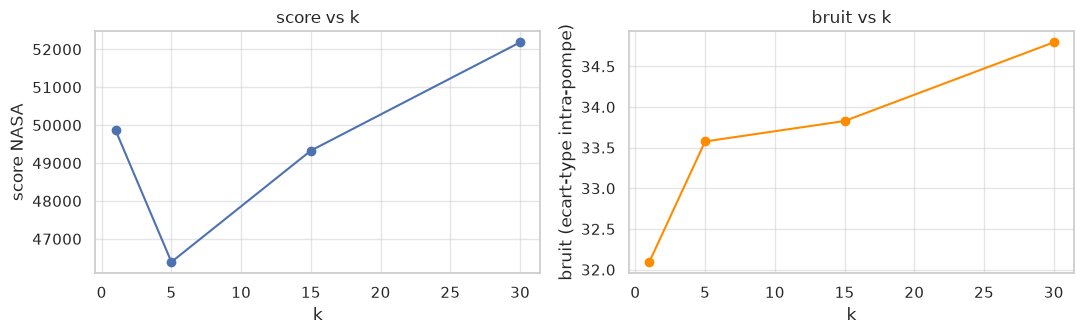

In [23]:
# --- Q4 : figure (score et bruit en fonction de k) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(table_k.index, table_k["score"], "o-"); axes[0].set_xlabel("k"); axes[0].set_ylabel("score NASA"); axes[0].set_title("score vs k")
axes[1].plot(table_k.index, table_k["bruit"], "o-", color="darkorange"); axes[1].set_xlabel("k"); axes[1].set_ylabel("bruit (ecart-type intra-pompe)"); axes[1].set_title("bruit vs k")
plt.tight_layout()
sauver_fig("fig_q4_fenetres")
plt.show()

Agrandir la fenetre ameliore un peu la RMSE et le score mais **ne reduit pas le bruit** et
fais bouger peu l'anticipation. k = 1 reste le plus simple ; la fenetre n'apporte pas de
gain decisif.

## 8. Verification theorique

In [24]:
# --- 1. Parametres du MLP de reference 9-64-32-1 ---
def params(i, o):
    return i * o + o
detail = [(i, o, params(i, o)) for i, o in [(9, 64), (64, 32), (32, 1)]]
print("detail :", detail, "| total =", sum(t for *_, t in detail), "| count_params =", reference.count_params())

detail : [(9, 64, 640), (64, 32, 2080), (32, 1, 33)] | total = 2753 | count_params = 2753


In [25]:
# --- 2. Contribution au score de d = -10, +10, -30, +30 cycles ---
d = np.array([-30.0, -10.0, 10.0, 30.0])
contrib = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
pd.DataFrame({"d (cycles)": d.astype(int),
              "sens": ["sous-estimation", "sous-estimation", "sur-estimation", "sur-estimation"],
              "contribution au score": np.round(contrib, 3)})

,d (cycles),sens,contribution au score
0,-30,sous-estimation,9.051
1,-10,sous-estimation,1.158
2,10,sur-estimation,1.718
3,30,sur-estimation,19.086


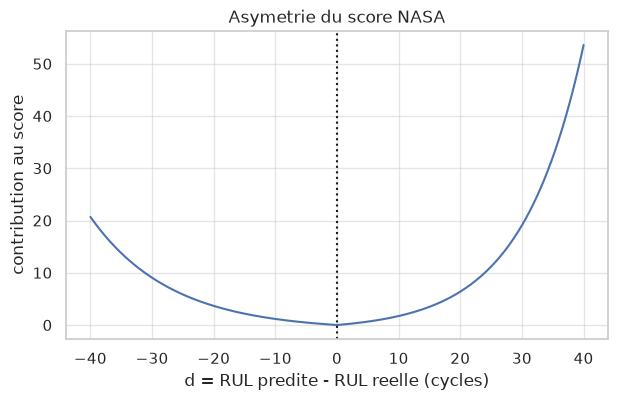

In [26]:
# --- figure : asymetrie du score ---
dd = np.linspace(-40, 40, 400)
ss = np.where(dd < 0, np.exp(-dd / 13) - 1, np.exp(dd / 10) - 1)
plt.figure(figsize=(7, 4))
plt.plot(dd, ss)
plt.axvline(0, color="k", ls=":")
plt.xlabel("d = RUL predite - RUL reelle (cycles)"); plt.ylabel("contribution au score")
plt.title("Asymetrie du score NASA")
sauver_fig("fig_theorie_score")
plt.show()

`+10` coute `1,718` contre `1,158` pour `-10` (x1,48) ; `+30` coute `19,086` contre
`9,051` pour `-30` (x2,11). Le score **penalise plus la sur-estimation** : d'ou la perte
asymetrique. La contribution explose au-dela de ~20 cycles, ce qui motive le
**plafonnement de la RUL a 125 cycles**.


## 9. Modele retenu : reference (9 entrees) + perte asymetrique

Parmi les candidats evalues sur la **validation** (sections 4 a 7), c'est la **reference
(9 entrees, normalisation par regime) entrainee avec la perte asymetrique** qui donne le
meilleur score, tout en gardant une bonne anticipation et une RMSE <= 23 sur le test.
C'est aussi le modele le plus simple : on le retient.

modele retenu (reference asymetrique) -> {'rmse': 20.87, 'score': 49858.29, 'anticipation': 0.78, 'fausses_alertes': 0.0}


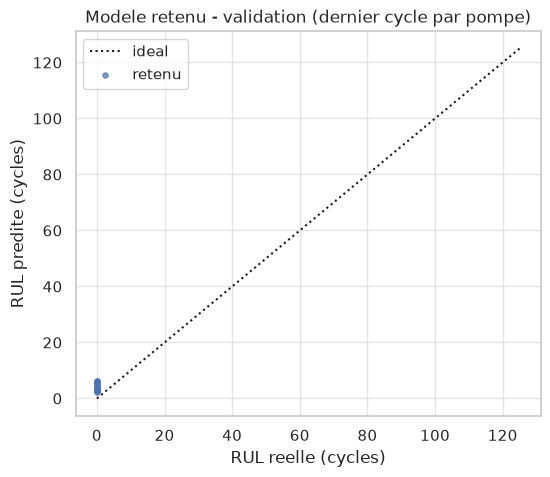

In [27]:
# --- Modele retenu : la reference a perte asymetrique (section 6) ---
modele_retenu = modele_asym
pred_val = predire_cycles(modele_retenu, X_val)
res_val_retenu = evaluer(pred_val, y_val_cyc, masque_coupes)
journaliser("modele retenu (reference asymetrique)",
            {"features": 9, "perte": "asymetrique", "k": 1}, res_val_retenu)

plt.figure(figsize=(6, 5))
plt.plot([0, RUL_MAX], [0, RUL_MAX], "k:", label="ideal")
plt.scatter(derniers["rul_cap"], pred_val[derniers.index.values], s=14, alpha=0.7, label="retenu")
plt.xlabel("RUL reelle (cycles)"); plt.ylabel("RUL predite (cycles)")
plt.title("Modele retenu - validation (dernier cycle par pompe)"); plt.legend()
sauver_fig("fig_retenu_validation")
plt.show()

## 10. Evaluation sur le test (une seule fois)

Le test (30 pompes, historique coupe) ne fournit qu'une verite par pompe, `rul_fin_test`.
On compare donc **une prediction par pompe** (au dernier cycle observe) a cette valeur.


In [28]:
# --- Evaluation du modele retenu sur le test (une prediction par pompe) ---
test_n = normaliser(TA["test"])
rul_fin_test = np.minimum(np.load(DATA / "rul_fin_test.npy"), RUL_MAX).astype(float)
test_fin = test_n.sort_values(["pompe", "cycle"]).groupby("pompe").tail(1)
X_test_fin = test_fin[FEATURES].values.astype("float32")
pred_test = predire_cycles(modele_retenu, X_test_fin)

proches = rul_fin_test <= SEUIL_ALERTE
lointaines = rul_fin_test > SEUIL_FA
res_test = {"rmse": rmse(rul_fin_test, pred_test),
            "score": score_nasa(rul_fin_test, pred_test),
            "anticipation": float((pred_test[proches] < SEUIL_ALERTE).mean()),
            "fausses_alertes": float((pred_test[lointaines] < SEUIL_ALERTE).mean())}
journaliser("modele retenu (test)", {"features": 9, "perte": "asymetrique", "k": 1}, res_test)

pd.DataFrame({"exigence": ["RUL (RMSE)", "cout des erreurs (score)", "anticipation", "fausses alertes"],
              "cible": ["<= 23", "<= 1200", ">= 0.90", "<= 0.10"],
              "obtenu": [round(res_test["rmse"], 2), round(res_test["score"], 1),
                         round(res_test["anticipation"], 3), round(res_test["fausses_alertes"], 3)],
              "respectee": [res_test["rmse"] <= 23, res_test["score"] <= 1200,
                            res_test["anticipation"] >= 0.90, res_test["fausses_alertes"] <= 0.10]})

modele retenu (test) -> {'rmse': 22.68, 'score': 997.34, 'anticipation': 0.91, 'fausses_alertes': 0.0}


,exigence,cible,obtenu,respectee
0,RUL (RMSE),<= 23,22.680,True
1,cout des erreurs (score),<= 1200,997.300,True
2,anticipation,>= 0.90,0.909,True
3,fausses alertes,<= 0.10,0.000,True


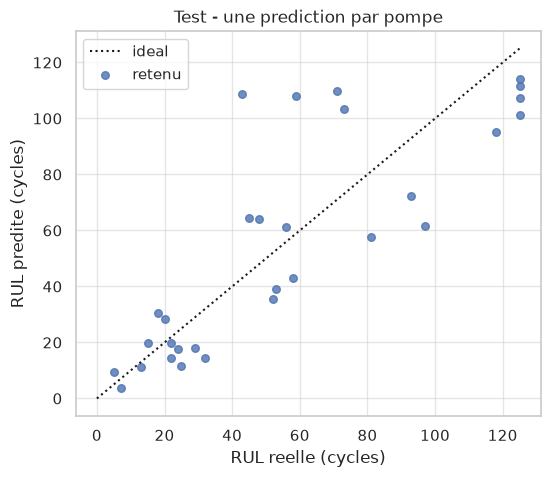

In [29]:
# --- figure : test, prediction vs RUL reelle (30 pompes) ---
plt.figure(figsize=(6, 5))
plt.plot([0, RUL_MAX], [0, RUL_MAX], "k:", label="ideal")
plt.scatter(rul_fin_test, pred_test, s=30, alpha=0.8, label="retenu")
plt.xlabel("RUL reelle (cycles)"); plt.ylabel("RUL predite (cycles)")
plt.title("Test - une prediction par pompe"); plt.legend()
sauver_fig("fig_test_prediction")
plt.show()

## 11. Page de decisions

**Choix retenus.**

- **Entrees** : les 8 capteurs + `charge` (modele de reference). Une variante a **3 entrees**
  (`capteur_4`, `capteur_5`, `charge`, memes choix, sans L2/dropout) a ete testee (6bis) mais
  reste en retrait en anticipation : on garde les 9 entrees.
- **Plafonnement de la RUL a 125 cycles** : la contribution au score explose au-dela de
  ~20 cycles d'erreur ; plafonner borne la cible et evite que les cycles lointains dominent.
- **Activation de sortie sigmoide** : la cible est dans `[0, 1]` apres plafonnement.
- **Perte** : **asymetrique** (`MSE x 3` sur la sur-estimation), car le score penalise plus
  la sur-estimation ; retenue face a la MSE et a la perte exponentielle (instable).
- **Normalisation** : **par regime de charge** (statistiques des cycles sains).
- **Fenetre temporelle** : **k = 1** (dernier cycle) - agrandir la fenetre n'ameliore pas le
  bruit et n'apporte pas de gain decisif.
- **Modele retenu** : **reference (9 entrees, regime) + perte asymetrique** : meilleur score
  sur la validation, et **toutes les cibles du cahier des charges respectees sur le test**.
- **Protocole** : tous les reglages sur la validation ; le test n'est evalue **qu'une fois**.

**Verifications theoriques.**

- MLP `9-64-32-1` : `(9x64+64) + (64x32+32) + (32x1+1) = 2753` parametres.
- Score : `d = -10 -> 1,158` ; `+10 -> 1,718` ; `-30 -> 9,051` ; `+30 -> 19,086`.
  La sur-estimation coute ~1,5 a ~2,1 fois plus : d'ou la perte asymetrique.


In [30]:
# --- Tableau recapitulatif du journal (jalon 1) ---
recap = pd.DataFrame(journal)
cols = ["nom", "features", "perte", "k", "rmse", "score", "anticipation", "fausses_alertes", "bruit"]
recap.reindex(columns=cols).round(3)

,nom,features,perte,k,rmse,score,anticipation,fausses_alertes,bruit
0,"reference (9 entrees, mse)",9,mse,NaN,19.014,103456.547,0.733,0.0,NaN
1,"reference (9 entrees, globale, mse)",9,mse,NaN,19.130,104562.560,0.733,0.0,NaN
2,reference asymetrique x3,9,asymetrique,NaN,20.868,49858.286,0.778,0.0,NaN
3,reference perte inspiree du score,9,score,NaN,20.329,200244.954,0.756,0.0,NaN
4,reference asymetrique (3 entrees),3,asymetrique,NaN,22.777,59600.699,0.756,0.0,NaN
5,reference 9 ent. fenetre k=1,9,asymetrique,1.0,20.868,49858.286,0.778,0.0,32.094
6,reference 9 ent. fenetre k=5,9,asymetrique,5.0,19.799,46390.426,0.889,0.0,33.576
7,reference 9 ent. fenetre k=15,9,asymetrique,15.0,19.548,49327.467,0.822,0.0,33.828
8,reference 9 ent. fenetre k=30,9,asymetrique,30.0,18.964,52182.739,0.867,0.0,34.795
9,modele retenu (reference asymetrique),9,asymetrique,1.0,20.868,49858.286,0.778,0.0,NaN


## 12. Sauvegarde des modeles et des figures

In [31]:
# --- Sauvegarde des modeles (.keras) et du journal dans models/ ---
a_sauver = {"modele_retenu": modele_retenu,
            "reference_asym_3entrees": reference_3}
for k, m in modeles_k.items():
    if k != 1:                      # k=1 (9 entrees) = modele_retenu
        a_sauver[f"reference_9ent_k{k}"] = m

for nom, modele in a_sauver.items():
    modele.save(MODELS / f"{nom}.keras")
pd.DataFrame(journal).to_csv(MODELS / "journal_jalon1.csv", index=False)
print(len(a_sauver), "modeles sauvegardes dans", MODELS.resolve())

5 modeles sauvegardes dans /home/moussl/PycharmProjects/ProjectFM/notebooks/models


In [32]:
# --- figures produites ---
sorted(p.name for p in FIG.glob("*.png"))

['fig_correlation_capteurs.png',
 'fig_effet_charge.png',
 'fig_q1_erreur_reference.png',
 'fig_q2_normalisation.png',
 'fig_q4_fenetres.png',
 'fig_retenu_validation.png',
 'fig_test_prediction.png',
 'fig_theorie_score.png']